In [ ]:
!pip install kagglehub

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS_PHASE1 = 10      # train the head
EPOCHS_PHASE2 = 15      # fine-tune
FINE_TUNE_AT = 100      # layers before this index stay frozen (MobileNetV2 has ~154 layers)
LR_PHASE1 = 1e-3
LR_PHASE2 = 1e-5        # must be much lower than phase 1
MODEL_PATH = "corn_leaf_model.h5"

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download("rabbityashow/corn-leaf-diseasesnlb")

for root, dirs, files in os.walk(path):
    print(root, "->", len(files), "files")

100%|██████████| 38.0M/38.0M [00:01<00:00, 25.8MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/rabbityashow/corn-leaf-diseasesnlb/versions/1 -> 0 files
/root/.cache/kagglehub/datasets/rabbityashow/corn-leaf-diseasesnlb/versions/1/Corn Healthy and Disease -> 0 files
/root/.cache/kagglehub/datasets/rabbityashow/corn-leaf-diseasesnlb/versions/1/Corn Healthy and Disease/diseased -> 1550 files
/root/.cache/kagglehub/datasets/rabbityashow/corn-leaf-diseasesnlb/versions/1/Corn Healthy and Disease/healthy -> 2567 files


In [ ]:
data_dir = os.path.join(path, "Corn Healthy and Disease")
print(os.listdir(data_dir))   # should print ['diseased', 'healthy']

['diseased', 'healthy']


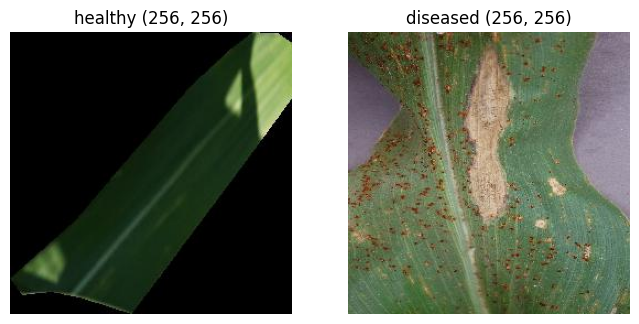

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, cls in zip(axes, ["healthy", "diseased"]):
    folder = os.path.join(data_dir, cls)
    img = Image.open(os.path.join(folder, os.listdir(folder)[0]))
    ax.imshow(img)
    ax.set_title(f"{cls} {img.size}")
    ax.axis("off")
plt.show()

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

class_names = train_ds.class_names
print("Class names:", class_names)   # index 0 = diseased, index 1 = healthy

Found 4117 files belonging to 2 classes.
Using 3294 files for training.
Found 4117 files belonging to 2 classes.
Using 823 files for validation.
Class names: ['diseased', 'healthy']


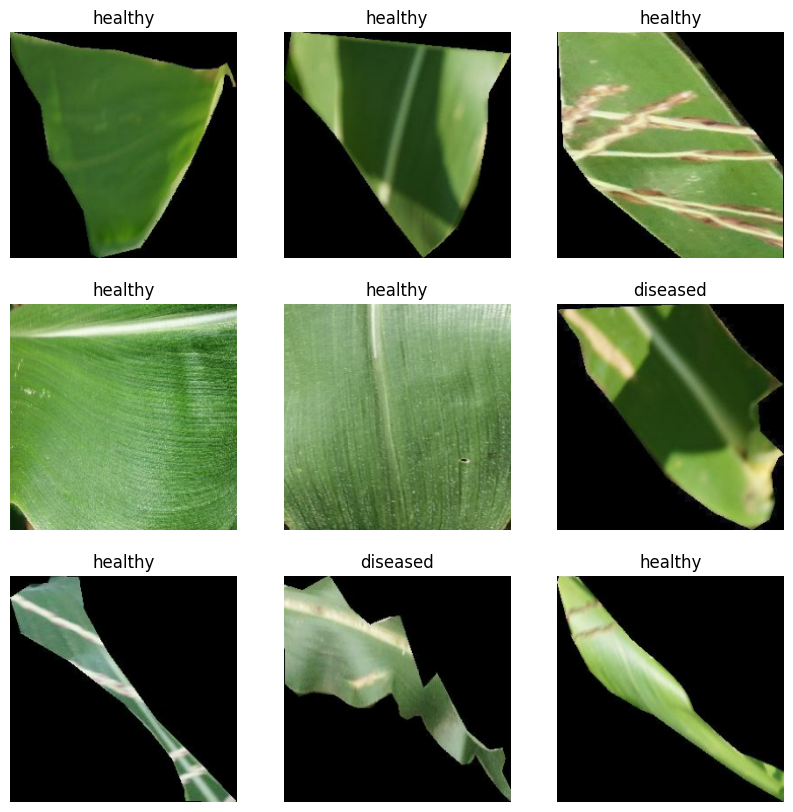

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i][0])])
        plt.axis("off")
plt.show()

In [ ]:
n_diseased = len(os.listdir(os.path.join(data_dir, "diseased")))
n_healthy = len(os.listdir(os.path.join(data_dir, "healthy")))
total = n_diseased + n_healthy

class_weight = {
    0: total / (2 * n_diseased),   # diseased
    1: total / (2 * n_healthy),    # healthy
}
print("Class weights:", class_weight)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

Class weights: {0: 1.3280645161290323, 1: 0.8019088430074016}


In [ ]:
# Data augmentation (only active during training)
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
], name="augmentation")

# Pretrained base
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False   # frozen for phase 1

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
# MobileNetV2 expects pixels in [-1, 1]. Rescaling is used instead of a Lambda layer so the .h5 file saves and loads cleanly.
x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
x = base_model(x, training=False)   # training=False keeps BatchNorm layers in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_PHASE1),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall")]
)

callbacks_phase1 = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    class_weight=class_weight,
    callbacks=callbacks_phase1
)

Epoch 1/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 29s 134ms/step - accuracy: 0.8084 - loss: 0.3983 - precision: 0.8582 - recall: 0.8284 - val_accuracy: 0.8457 - val_loss: 0.3146 - val_precision: 0.8611 - val_recall: 0.9023 - learning_rate: 0.0010
Epoch 2/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 24s 70ms/step - accuracy: 0.8491 - loss: 0.3136 - precision: 0.8718 - recall: 0.8875 - val_accuracy: 0.8603 - val_loss: 0.2913 - val_precision: 0.8467 - val_recall: 0.9521 - learning_rate: 0.0010
Epoch 3/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - accuracy: 0.8379 - loss: 0.3119 - precision: 0.8669 - recall: 0.8729 - val_accuracy: 0.8554 - val_loss: 0.2852 - val_precision: 0.8353 - val_recall: 0.9617 - learning_rate: 0.0010
Epoch 4/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - accuracy: 0.8458 - loss: 0.2983 - precision: 0.8711 - recall: 0.8822 - val_accuracy: 0.8518 - val_loss: 0.2969 - val_precision: 0.8413 - val_recall: 0.9444 - learning_rate: 0.0010
Epoch 5/10
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - ac

In [ ]:
base_model.trainable = True
print("Layers in base model:", len(base_model.layers))

# Freeze everything before FINE_TUNE_AT
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

# Keep BatchNorm layers frozen even in the unfrozen part
for layer in base_model.layers[FINE_TUNE_AT:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_count = sum(1 for l in base_model.layers if l.trainable)
print("Trainable layers in base model:", trainable_count)

# Recompile is required after changing trainable flags
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LR_PHASE2),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall")]
)

callbacks_phase2 = [
    keras.callbacks.ModelCheckpoint(
        "best_finetuned.weights.h5",
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
]

# Continue the epoch count from phase 1
initial_epoch = len(history1.history["loss"])

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=initial_epoch + EPOCHS_PHASE2,
    initial_epoch=initial_epoch,
    class_weight=class_weight,
    callbacks=callbacks_phase2
)

Layers in base model: 154
Trainable layers in base model: 36
Epoch 11/25
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.8729 - loss: 0.2647 - precision: 0.8970 - recall: 0.9035
Epoch 11: val_loss improved from None to 0.29697, saving model to best_finetuned.weights.h5

Epoch 11: finished saving model to best_finetuned.weights.h5
103/103 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - accuracy: 0.8658 - loss: 0.2665 - precision: 0.8931 - recall: 0.8905 - val_accuracy: 0.8348 - val_loss: 0.2970 - val_precision: 0.9124 - val_recall: 0.8180 - learning_rate: 1.0000e-05
Epoch 12/25
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.8749 - loss: 0.2659 - precision: 0.8964 - recall: 0.9010
Epoch 12: val_loss improved from 0.29697 to 0.26878, saving model to best_finetuned.weights.h5

Epoch 12: finished saving model to best_finetuned.weights.h5
103/103 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.8813 - loss: 0.2593 - precision: 0.8976 - recall: 0.9130 - val_accuracy: 0.8591 - val_loss:

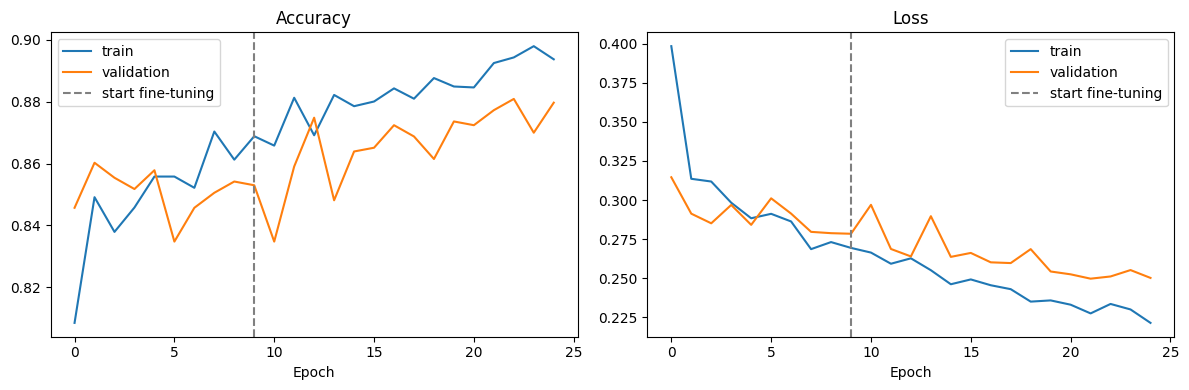

In [ ]:
def join(key):
    return history1.history[key] + history2.history[key]

acc, val_acc = join("accuracy"), join("val_accuracy")
loss, val_loss = join("loss"), join("val_loss")
split = len(history1.history["loss"]) - 1

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label="train")
plt.plot(val_acc, label="validation")
plt.axvline(split, color="gray", linestyle="--", label="start fine-tuning")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="train")
plt.plot(val_loss, label="validation")
plt.axvline(split, color="gray", linestyle="--", label="start fine-tuning")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
results = model.evaluate(val_ds, verbose=0)
for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")

loss: 0.2498
compile_metrics: 0.8773


              precision    recall  f1-score   support

    diseased       0.86      0.79      0.82       301
     healthy       0.88      0.93      0.91       522

    accuracy                           0.88       823
   macro avg       0.87      0.86      0.87       823
weighted avg       0.88      0.88      0.88       823



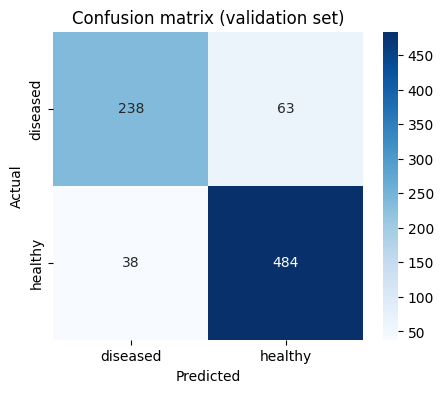

In [ ]:
# Collect true labels and predictions in the same pass so they always line up
y_true, y_prob = [], []
for images, labels in val_ds:
    y_prob.extend(model.predict(images, verbose=0).ravel())
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true).astype(int)
y_pred = (np.array(y_prob) > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (validation set)")
plt.show()

In [ ]:
model.save(MODEL_PATH)
print("Saved:", MODEL_PATH, f"({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

Saved: corn_leaf_model.h5 (26.1 MB)


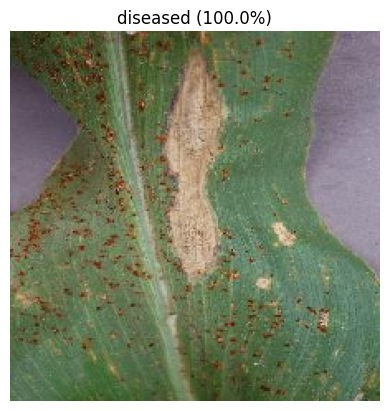

Actual: diseased | Predicted: ('diseased', 0.9999999979194967)


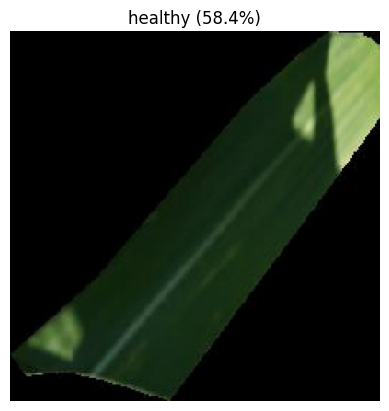

Actual: healthy | Predicted: ('healthy', 0.5844337344169617)


In [ ]:
loaded_model = tf.keras.models.load_model(MODEL_PATH)

def predict_image(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    arr = tf.keras.utils.img_to_array(img)
    arr = np.expand_dims(arr, axis=0)          # no manual scaling: the model rescales internally
    prob = float(loaded_model.predict(arr, verbose=0)[0][0])
    label = class_names[int(prob > 0.5)]
    confidence = prob if prob > 0.5 else 1 - prob
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{label} ({confidence:.1%})")
    plt.show()
    return label, confidence

# Try one image from each class
for cls in class_names:
    folder = os.path.join(data_dir, cls)
    sample = os.path.join(folder, os.listdir(folder)[0])
    print("Actual:", cls, "| Predicted:", predict_image(sample))

In [ ]:
# Option A: download to your computer
from google.colab import files
files.download(MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Option B: copy to Google Drive
!cp {MODEL_PATH} /content/drive/MyDrive/
print("Copied to Drive")

Copied to Drive
